# Maxwell 3D grating coupler (fiber-to-chip)
A silicon-on-insulator (SOI) waveguide grating that lifts guided light off the
chip into a free-space beam aimed at a notional optical fiber. This is the
canonical photonic-integrated-circuit input/output structure: you cannot
butt-couple a ~10 um fiber mode to a sub-micron waveguide, so a periodic grating
diffracts the guided mode upward (out of plane) into a beam the fiber can catch.

This is a genuine 3D structure (no 2D side-view reduction): a finite-width 220 nm
silicon waveguide on a SiO2 buried oxide (BOX) with an air top-cladding, real
material indices, and a partial etch grating. The simulation axes are
  * x = propagation along the chip,
  * y = lateral (waveguide WIDTH direction),
  * z = vertical (the layer stack: BOX below, Si core, air above; the beam
        radiates up toward +z).

The fundamental waveguide mode is launched from the left in the unetched guide.
Where it reaches the partially-etched grating, each tooth scatters a little
power; the teeth add coherently into a single diffracted beam leaving the surface
at an angle set by the grating equation ``n_air sin(theta) = n_eff - lambda / period``
(first diffracted order), where n_eff belongs to the periodic region rather than to the
unetched guide. The run reports the angle the beam actually leaves at.

Why a full-wave solver (not ray tracing): coupling is sub-wavelength tooth
scattering plus near-field overlap with the fiber mode -- diffraction, not
refraction. The Modified Born Series solver captures the whole near-field-to-
stand-off region in one CW solve. Quasi-TE polarization (dominant E along the
width, y) -- the usual silicon-photonics grating mode.

The launch is the guide's own fundamental mode: the engine solves the full-vector
modes of the (y, z) cross-section of the simulation grid when the run starts, with its
finite-difference mode solver, and drives the one asked for one way along the guide.
The source is a specification -- where, which polarization, which order, how long a
drive -- and the run reports the mode it solved.

The device can be described to the solver in three ways, chosen by ``GEOMETRY``: as a
voxel array painted at the simulation pitch, where every edge lands on a voxel
boundary; as that array plus a second one over the grating zone painted twice as fine
along x and z, which the service averages into the simulation voxels so that an edge
between two voxels is a mixed voxel; or as box primitives the service voxelises itself
with sub-pixel averaging. The 130 nm etch is 6.5 voxels deep and the tooth edges fall
mid-voxel, so the three differ exactly where it matters for the beam angle. A final
cell compares the paths that have run.

Size: 334.4 Mvoxel including boundaries, 17.44 GB of memory (service estimate).

In [1]:
import json

import numpy as np

from wavesimpro import Box, Medium, Setup, VoxelArray, create_mode_source, create_monitor, submit
from wsutils import output_dir

NAME = "mx_grating_coupler"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

# How the device reaches the solver: "array" (voxels at the simulation pitch),
# "array_fine" (the same, plus the grating zone at half the pitch along x and z, averaged
# by the service) or "primitives" (boxes, sub-pixel averaged by the service).
GEOMETRY = "primitives"

### Parameters (edit these to rescale)

In [2]:
wavelength = 1.55  # design wavelength in micrometer (μm)
pixel_size = 0.02  # grid spacing (μm); ~6.5 px across the 130 nm etch, 33 px per period

n_si = 3.476   # silicon core
n_box = 1.444  # SiO2 buried oxide / cladding
n_air = 1.0    # air top cladding

t_core = 0.22   # Si core thickness, vertical z (μm)
W_wg = 2.5      # waveguide / grating width, lateral y (μm)

# Vertical layer stack (z increases upward; beam radiates toward +z into air).
box_thick = 1.30  # BOX thickness below the core (μm)
air_above = 3.60  # air above the core -- room for the beam to lift off (μm)
sim_z = box_thick + t_core + air_above
z_core_bot = box_thick
z_core_top = box_thick + t_core

# Lateral window
sim_y = W_wg + 2.0  # width + cladding/boundary margin (μm)
yc = sim_y / 2

# Grating (partial etch into the top of the core). Period chosen for an off-normal
# first-order beam; the angle it actually leaves at is measured from the solved field.
period = 0.66    # grating pitch Λ (μm)
duty = 0.5       # tooth fraction of the period
etch_depth = 0.13  # partial etch depth from the core top (μm)
n_teeth = 18
grating_start = 3.0  # x where the grating begins (μm)

# The mode is launched one way by driving a length of guide with the mode's own phase,
# so the backward wave cancels. The drive is centred on x_source; its end stays clear
# of the first tooth.
x_source = 1.6        # centre of the driven length (μm)
drive_length = 2.0    # μm of guide driven

# Absorbing boundary, per axis: size each face by the power that reaches it. This device
# radiates through z by design, so z stays thick, with more of it below than above.
boundary_widths = [4.0 * wavelength, 1.0 * wavelength,
                   (2.48 * wavelength, 1.52 * wavelength)]

sim_x = grating_start + n_teeth * period + 3.0  # lead-in + grating + tail

nx = int(round(sim_x / pixel_size))
ny = int(round(sim_y / pixel_size))
nz = int(round(sim_z / pixel_size))
kz_core_top = int(round(z_core_top / pixel_size))
jy0 = int(round((yc - W_wg / 2) / pixel_size))
jy1 = int(round((yc + W_wg / 2) / pixel_size))

### Emission-angle target

In [3]:
# Fibre grating couplers are aimed off normal on purpose: at exact normal incidence the
# second order reflects straight back down the waveguide. This period puts the first order
# near 20 deg, and the run measures where it lands.
#
# The grating equation n_air*sin(theta) = n_eff - lambda/period gives the angle, but n_eff
# there belongs to the PERIODIC region, not to the unetched input guide. It is a Bloch index
# of the tooth-groove structure, not an average of the two segment indices, so the closed
# form does not pin it down -- and since lambda/period is subtracted from it, a small index
# error becomes a large angle error.
ANGLE_TARGET = 20.0  # degrees from normal, first order
print(f"Grating: period={period} um, {n_teeth} teeth, {duty:.0%} duty, "
      f"{etch_depth*1e3:.0f} nm etch")
print(f"  designed for a first-order beam near {ANGLE_TARGET:.0f} deg from normal")

Grating: period=0.66 um, 18 teeth, 50% duty, 130 nm etch
  designed for a first-order beam near 20 deg from normal


### Build the 3D geometry

In [4]:
# The teeth: silicon kept at full thickness. Everything between them is etched down by
# etch_depth; the lead-in and the tail are unetched.
teeth = [(0.0, grating_start + duty * period)]
teeth += [(grating_start + k * period, grating_start + k * period + duty * period)
          for k in range(1, n_teeth)]
teeth += [(grating_start + n_teeth * period, sim_x)]


def paint_array(pitch, region=((0.0, 0.0, 0.0), None)):
    """Permittivity on a grid of spacing ``pitch`` = (dx, dy, dz) over ``region`` =
    (origin, size) in μm (the whole domain by default): BOX below, the etched silicon slab,
    the teeth on top of it, air everywhere else. Edges land on the nearest grid line."""
    origin, size = region
    size = size or (sim_x, sim_y, sim_z)
    shape = tuple(int(round(s / d)) for s, d in zip(size, pitch))
    at = lambda value, axis: min(max(int(round((value - origin[axis]) / pitch[axis])), 0), shape[axis])
    n = np.full(shape, n_air, dtype=np.complex64)
    kb, kt, ke = at(z_core_bot, 2), at(z_core_top, 2), at(z_core_top - etch_depth, 2)
    j0, j1 = at(yc - W_wg / 2, 1), at(yc + W_wg / 2, 1)
    n[:, :, :kb] = n_box                     # BOX slab (all x, y)
    n[:, j0:j1, kb:ke] = n_si                # etched slab, full length
    for xa, xb in teeth:
        n[at(xa, 0):at(xb, 0), j0:j1, ke:kt] = n_si
    return n ** 2


air, sio2, silicon = Medium("Air", n_air), Medium("SiO2", n_box), Medium("Si", n_si)


def box(name, medium, x_span, y_span, z_span):
    """A box from spans in grid-corner coordinates (μm), sub-pixel averaged. The solver's
    coordinates are centred on the domain."""
    centre = [(a + b) / 2 - s / 2 for (a, b), s in zip((x_span, y_span, z_span), (sim_x, sim_y, sim_z))]
    size = [b - a for a, b in (x_span, y_span, z_span)]
    return Box(n=medium, name=name, center=centre, size=size, subpixel=True)


setup = Setup(wavelength, pixel_size, (nx, ny, nz), boundary_widths=boundary_widths,
              background=air, name=f"{NAME} ({GEOMETRY})")
if GEOMETRY in ("array", "array_fine"):
    # At the simulation pitch the array is copied voxel for voxel.
    permittivity = paint_array((pixel_size, pixel_size, pixel_size))
    setup.set_permittivity(permittivity)
if GEOMETRY == "array_fine":
    # The grating zone again at half the pitch along x and z, placed over the array
    # above. Its edges sit on simulation voxel boundaries; the service averages each
    # 2 x 1 x 2 block of its cells into one simulation voxel. Its position is the block's
    # centre in domain-centred coordinates.
    fine_pitch = (pixel_size / 2, pixel_size, pixel_size / 2)
    fine_origin = (grating_start - 0.5, yc - W_wg / 2 - 0.3, z_core_bot)
    fine_size = (n_teeth * period + 1.0, W_wg + 0.6, 0.3)
    permittivity_fine = paint_array(fine_pitch, (fine_origin, fine_size))
    centre = [o + s / 2 - d / 2 for o, s, d in zip(fine_origin, fine_size, (sim_x, sim_y, sim_z))]
    setup.add(VoxelArray(array=permittivity_fine, name="grating_zone", n=air, pixel_size=fine_pitch,
                         center=centre, subpixel=True))
elif GEOMETRY == "primitives":
    primitives = [box("box_oxide", sio2, (0, sim_x), (0, sim_y), (0, z_core_bot)),
                  box("si_slab", silicon, (0, sim_x), (yc - W_wg / 2, yc + W_wg / 2),
                      (z_core_bot, z_core_top - etch_depth))]
    primitives += [box(f"tooth_{k}", silicon, span, (yc - W_wg / 2, yc + W_wg / 2),
                       (z_core_top - etch_depth, z_core_top)) for k, span in enumerate(teeth)]
    setup.add(*primitives)
elif GEOMETRY != "array":
    raise ValueError(f"GEOMETRY must be 'array', 'array_fine' or 'primitives', got {GEOMETRY!r}")
mvox = nx * ny * nz / 1e6
print(f"Interior grid: {nx} x {ny} x {nz} = {mvox:.1f} Mvoxel  (px={pixel_size} um); geometry as {GEOMETRY}"
      + (f", array {permittivity.shape}" if GEOMETRY != "primitives" else f", {len(primitives)} boxes")
      + (f" + fine block {permittivity_fine.shape}" if GEOMETRY == "array_fine" else ""))

Interior grid: 894 x 225 x 256 = 51.5 Mvoxel  (px=0.02 um); geometry as primitives, 21 boxes


### Source: the engine solves and launches the waveguide mode

In [5]:
# The cut is the (y, z) layer where the drive ends. At run start the engine solves the
# full-vector modes of that layer of the voxelised device and drives the quasi-TE
# fundamental (E along y, across the guide) over ``drive_length`` of guide ending at the
# cut. The solve window is the whole layer: the guide is the only core in it.
i_drive_end = int(round((x_source + drive_length / 2) / pixel_size))
source = create_mode_source(name="TE0", axis="x", plane_index=i_drive_end, direction=+1,
                            polarization="TE", order=0, drive_length_um=drive_length,
                            engine_solver="fd")
print(f"Mode source: quasi-TE fundamental, {drive_length} um of guide driven towards +x, "
      f"ending at x = {i_drive_end * pixel_size:.2f} um")

y_mid = (jy0 + jy1) // 2

Mode source: quasi-TE fundamental, 2.0 um of guide driven towards +x, ending at x = 2.60 um


### Monitor: return just the x-z cut-plane this figure plots

In [6]:
# A monitor crops the result to this plane server-side, so only a thin slice is
# transferred instead of the full volume. The monitor is a thin slab through the guide
# centre; voxel index i on an n-voxel axis sits at (i + 0.5 - n/2)*px in domain-centred
# world coordinates.
y_world = (y_mid + 0.5 - ny / 2) * pixel_size
monitor = create_monitor(
    name="cutplane",
    center_x=0.0, center_y=y_world, center_z=0.0,
    size_x=nx * pixel_size, size_y=3 * pixel_size, size_z=nz * pixel_size,
)

### Run: submit the setup, read the monitor and the solved mode

In [7]:
# A setup is one document: the domain and grid, air as background, the device, the source
# and the monitor. ``submit`` checks it, uploads any array, saves it on a new project and
# starts the run.
setup.add(source, monitor)
print(f"  monitor: y = {y_world:+.4f} um, {nx * pixel_size:.2f} x {nz * pixel_size:.2f} um, 3 voxels thick")

run = submit(setup).wait()
elapsed = run.elapsed
print(f"Time {elapsed:.1f} s; Iterations {run.iterations}; Residual {run.residual_norm}")

# The monitor's field and the record of the mode the engine solved, kept per geometry
# path so the paths can be compared.
u =run.get_monitors()[0]
np.save(f"{OUTPUT_DIR}/cutplane_{GEOMETRY}.npy", u)
launched = run.mode_sources()[0]
with open(f"{OUTPUT_DIR}/modeSources_{GEOMETRY}.json", "w") as f:
    json.dump(launched, f, indent=1)
neff = launched["neff"]["re"]
share = launched["eShare"]
print(f"Launched mode: neff = {neff:.4f}; E energy {share['y']:.1%} across, "
      f"{share['z']:.1%} vertical, {share['x']:.1%} longitudinal")

# Visualization cut-plane: vertical x-z slice through the guide centre (the mid y index).
ey = u[1]
field_side = ey[:, ey.shape[1] // 2, :]

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

intensity = np.abs(field_side) ** 2
intensity /= intensity.max()
extent = [0, sim_x, 0, sim_z]

  [!] Mode source 'TE0': linear absorbing layers at the two x ends (310 and 310 px) reflect a launched guided mode by about c_m / (W + 0.66), c_m a property of the mode (the engine reports it in the run notes); for 1e-3 that takes hundreds of pixels. boundary_profile='cubic' needs 233 px (4.67 um) per end.


  monitor: y = +0.0000 um, 17.88 x 5.12 um, 3 voxels thick

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 31cb90d2-5c57-4997-9910-f935630e5d11
  Version   : fa0e6bf7-0937-4263-894f-2e972b18a688
  Command   : daf80562-936f-4ee8-ace6-fe453453b3e5
  Mode      : Maxwell (vectorial)
  Domain    : 894x225x256 voxels  lambda=1.55 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 152.1 s; Iterations 818; Residual 9.799311e-07
Launched mode: neff = 2.8113; E energy 98.6% across, 0.1% vertical, 1.3% longitudinal


### Where the beam goes

Emitted beam: +18.1 deg from normal against a 20 deg target
  implies n_eff 2.658 for the periodic region


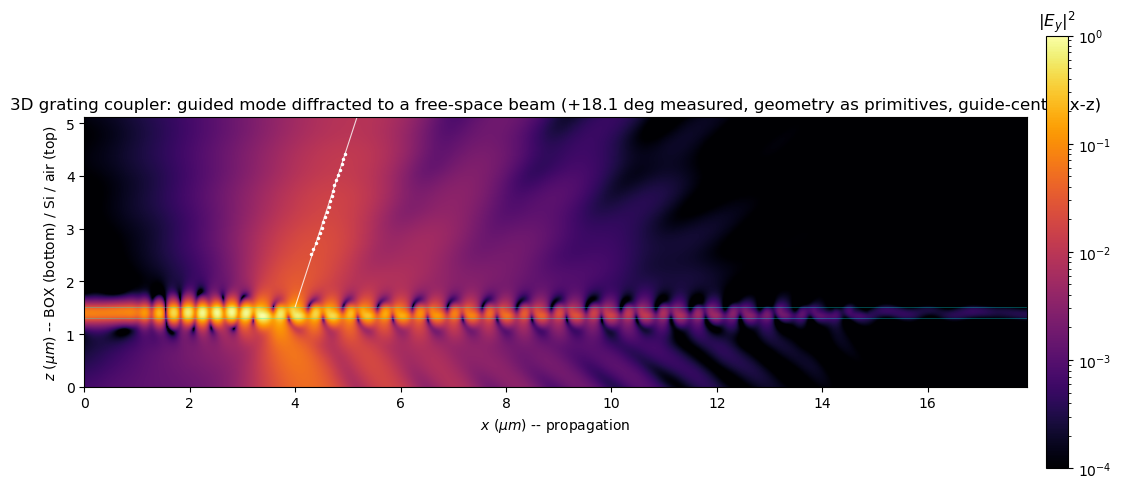

In [8]:
def beam_angle(intensity):
    """Degrees from normal of the emitted beam: the brightest point at each height in the
    air, 1 to 3 um above the core, with a line fitted through them. Tracking the peak
    rather than the intensity centroid matters: the centroid is dragged by the broad tails
    and by light still in the guide, so it shifts with the integration window."""
    heights, peaks = [], []
    for h in np.arange(1.0, min(3.0, air_above - 0.6), 0.1):
        k = kz_core_top + int(round(h / pixel_size))
        if k >= intensity.shape[1]:
            break
        line = intensity[:, k]
        j = int(np.argmax(line))
        curv = line[j - 1] - 2 * line[j] + line[j + 1] if 0 < j < len(line) - 1 else 0.0
        sub = (line[j - 1] - line[j + 1]) / (2 * curv) if curv else 0.0   # sub-voxel peak
        heights.append(h)
        peaks.append((j + sub) * pixel_size)
    slope, offset = np.polyfit(heights, peaks, 1)
    return float(np.degrees(np.arctan(slope))), np.array(heights), np.array(peaks), (slope, offset)


def draw_beam(ax, heights, peaks, fit):
    """The tracked peaks and the fitted line, from the core top up through the air."""
    ax.plot(peaks, z_core_top + heights, ".", color="white", ms=3)
    zz = np.array([0.0, air_above])
    ax.plot(fit[1] + fit[0] * zz, z_core_top + zz, color="white", lw=0.8, alpha=0.8)


measured_angle, beam_h, beam_x, beam_fit = beam_angle(intensity)
n_eff_implied = np.sin(np.radians(measured_angle)) * n_air + wavelength / period
print(f"Emitted beam: {measured_angle:+.1f} deg from normal against a "
      f"{ANGLE_TARGET:.0f} deg target")
print(f"  implies n_eff {n_eff_implied:.3f} for the periodic region")
with open(f"{OUTPUT_DIR}/results_{GEOMETRY}.json", "w") as f:
    json.dump(dict(geometry=GEOMETRY, angle_deg=measured_angle, n_eff_periodic=n_eff_implied,
                   neff_launched=neff, e_share=share, iterations=run.iterations), f, indent=1)

plt.figure(figsize=(11, 5))
plt.imshow(intensity.T, cmap="inferno", origin="lower", extent=extent, norm=LogNorm(vmin=1e-4, vmax=1.0), aspect="equal")
cbar = plt.colorbar(fraction=0.025, pad=0.02)
cbar.ax.set_title(r"$|E_y|^2$")
for z_line in (z_core_bot, z_core_top):
    plt.axhline(z_line, color="cyan", lw=0.5, alpha=0.4)
draw_beam(plt.gca(), beam_h, beam_x, beam_fit)
plt.xlabel(r"$x~(\mu m)$ -- propagation")
plt.ylabel(r"$z~(\mu m)$ -- BOX (bottom) / Si / air (top)")
plt.title(f"3D grating coupler: guided mode diffracted to a free-space beam "
          f"({measured_angle:+.1f} deg measured, geometry as {GEOMETRY}, guide-center x-z)")
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIR}/mx_grating_coupler_{GEOMETRY}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{OUTPUT_DIR}/mx_grating_coupler_{GEOMETRY}.pdf", bbox_inches="tight")
plt.show()
plt.close("all")

### The geometry paths that have run, side by side

In [9]:
# Every path that has left its results in OUTPUT_DIR is compared here: the beam angle, the
# periodic-region index it implies, the launched mode, the iteration count, and the field on
# the plotted plane against the box-primitive path when that one is present.
paths = {}
for tag in ("array", "array_fine", "primitives"):
    try:
        with open(f"{OUTPUT_DIR}/results_{tag}.json") as f:
            paths[tag] = json.load(f)
        v = np.load(f"{OUTPUT_DIR}/cutplane_{tag}.npy")
        paths[tag]["ey"] = v[1][:, v.shape[2] // 2, :]
    except FileNotFoundError:
        pass

if len(paths) > 1:
    ref_tag = "primitives" if "primitives" in paths else list(paths)[-1]
    e_ref = paths[ref_tag]["ey"]
    print(f"{'geometry':<12s} {'angle (deg)':>12s} {'n_eff periodic':>15s} {'n_eff launched':>15s} "
          f"{'iterations':>11s} {'corr. vs ' + ref_tag:>20s} {'rel. rms diff':>14s}")
    for tag, r in paths.items():
        e = r["ey"]
        s = np.vdot(e_ref, e) / np.vdot(e_ref, e_ref)            # one amplitude and phase factor
        corr = abs(np.vdot(e, e_ref * s)) / np.sqrt(np.vdot(e, e).real * np.vdot(e_ref * s, e_ref * s).real)
        rms = np.sqrt(np.mean(np.abs(e - e_ref * s) ** 2) / np.mean(np.abs(e) ** 2))
        print(f"{tag:<12s} {r['angle_deg']:>+12.2f} {r['n_eff_periodic']:>15.4f} {r['neff_launched']:>15.4f} "
              f"{str(r['iterations']):>11s} {corr:>20.6f} {rms:>14.3e}")

    fig, axes = plt.subplots(len(paths), 1, figsize=(11, 3.2 * len(paths)), sharex=True)
    for ax, (tag, r) in zip(np.atleast_1d(axes), paths.items()):
        d = np.abs(r["ey"]) ** 2
        ax.imshow((d / d.max()).T, cmap="inferno", origin="lower", extent=extent,
                  norm=LogNorm(vmin=1e-4, vmax=1.0), aspect="equal")
        draw_beam(ax, *beam_angle(d / d.max())[1:])
        ax.set_title(f"{tag}: {r['angle_deg']:+.2f} deg")
        ax.set_ylabel(r"$z~(\mu m)$")
    np.atleast_1d(axes)[-1].set_xlabel(r"$x~(\mu m)$")
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/mx_grating_coupler_geometry_paths.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close("all")